<a href="https://colab.research.google.com/github/202343500268-NaufalDaniswara/202343500268-Machine-Learning/blob/main/Latihan_BAB8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import library yang dibutuhkan
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Load dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Split data menjadi train dan test (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Dataset berhasil dimuat dan dibagi.")
print(f"Bentuk X_train: {X_train.shape}, Bentuk X_test: {X_test.shape}")

Dataset berhasil dimuat dan dibagi.
Bentuk X_train: (455, 30), Bentuk X_test: (114, 30)


In [2]:
print("--- Praktikum 1: Perbandingan Kernel ---")

# Kode dari gambar (Praktikum 8.7)
for kernel in ["linear", "poly", "rbf"]:
    # Membuat pipeline dengan StandardScaler dan SVC
    model = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel=kernel))])

    # Melatih model
    model.fit(X_train, y_train)

    # Memprediksi dan menghitung akurasi
    acc = accuracy_score(y_test, model.predict(X_test))

    # Menampilkan hasil
    print(f"Kernel {kernel}: akurasi = {acc:.3f}")

--- Praktikum 1: Perbandingan Kernel ---
Kernel linear: akurasi = 0.956
Kernel poly: akurasi = 0.868
Kernel rbf: akurasi = 0.982



--- Praktikum 2: Visualisasi Decision Boundary ---


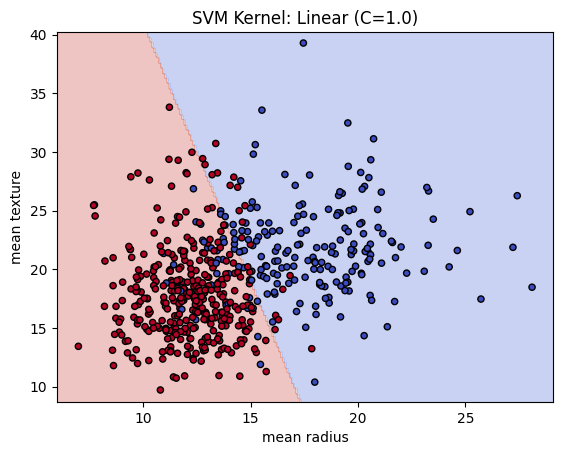

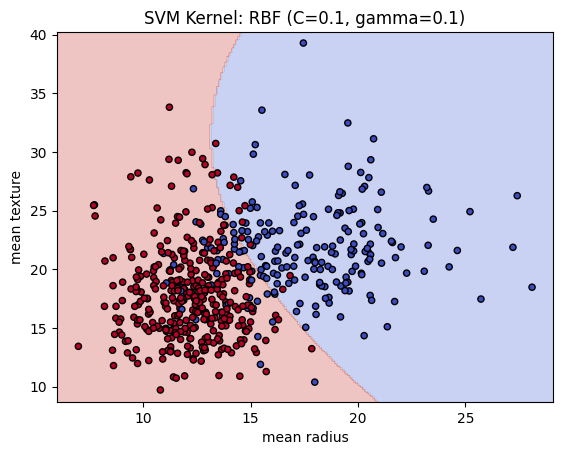

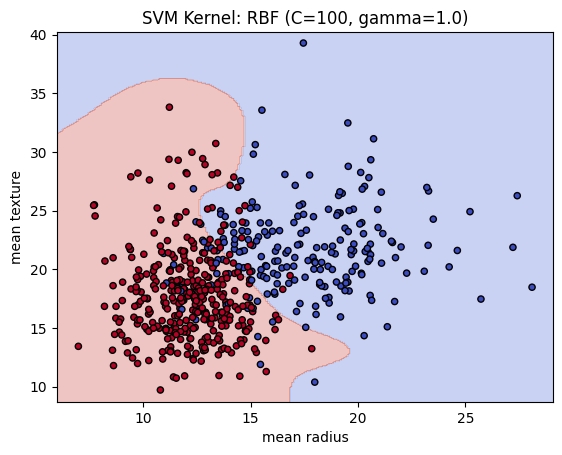

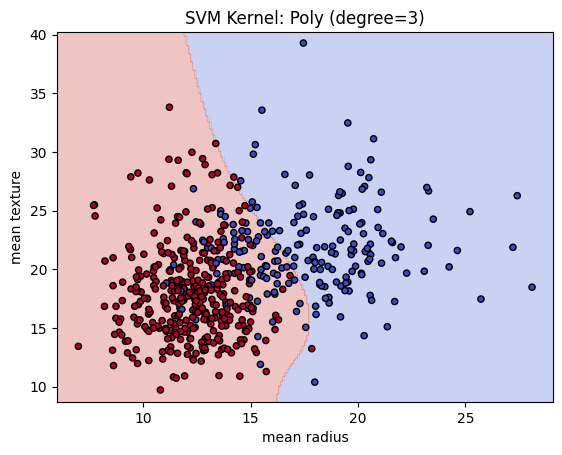

In [3]:
print("\n--- Praktikum 2: Visualisasi Decision Boundary ---")

# 1. Pilih 2 fitur (contoh: 'mean radius' [kolom 0] dan 'mean texture' [kolom 1])
feature_indices = [0, 1]
X_2f = X[:, feature_indices]
y_2f = y

# Split ulang khusus untuk data 2 fitur ini
X_train_2f, X_test_2f, y_train_2f, y_test_2f = train_test_split(X_2f, y_2f, test_size=0.2, random_state=42)

# 2. Fungsi untuk memplot decision boundary
def plot_decision_boundary(model, X, y, title):
    # Menentukan batas plot
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                         np.arange(y_min, y_max, 0.1))

    # Memprediksi seluruh area grid
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Plot contour dan scatter points
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap='coolwarm', s=20)
    plt.xlabel(data.feature_names[feature_indices[0]])
    plt.ylabel(data.feature_names[feature_indices[1]])
    plt.title(title)
    plt.show()

# 3. Latih SVM dengan beberapa kombinasi dan visualisasikan
# Catatan: Parameter C dan gamma sangat mempengaruhi bentuk boundary.

# Kombinasi A: Kernel Linear
model_linear = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="linear", C=1.0))])
model_linear.fit(X_train_2f, y_train_2f)
plot_decision_boundary(model_linear, X_2f, y_2f, "SVM Kernel: Linear (C=1.0)")

# Kombinasi B: Kernel RBF (C kecil, gamma kecil)
model_rbf_1 = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="rbf", C=0.1, gamma=0.1))])
model_rbf_1.fit(X_train_2f, y_train_2f)
plot_decision_boundary(model_rbf_1, X_2f, y_2f, "SVM Kernel: RBF (C=0.1, gamma=0.1)")

# Kombinasi C: Kernel RBF (C besar, gamma besar)
model_rbf_2 = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="rbf", C=100, gamma=1.0))])
model_rbf_2.fit(X_train_2f, y_train_2f)
plot_decision_boundary(model_rbf_2, X_2f, y_2f, "SVM Kernel: RBF (C=100, gamma=1.0)")

# Kombinasi D: Kernel Polynomial
model_poly = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel="poly", degree=3, C=1.0))])
model_poly.fit(X_train_2f, y_train_2f)
plot_decision_boundary(model_poly, X_2f, y_2f, "SVM Kernel: Poly (degree=3)")